In [29]:
import seaborn as sns
# Load the 'taxis' dataset
df=sns.load_dataset("taxis")

In [30]:
df.to_csv("taxis.csv", index=False)

In [31]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [32]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [33]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

In [34]:
df = df.dropna(subset=["pickup_zone", "pickup_borough"])

In [35]:
df["pickup_zone"] = df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])

In [36]:
df = df.dropna(subset=["pickup_zone","dropoff_zone"])

In [37]:
print(df.isnull().sum())
print(df.shape)

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
(6383, 14)


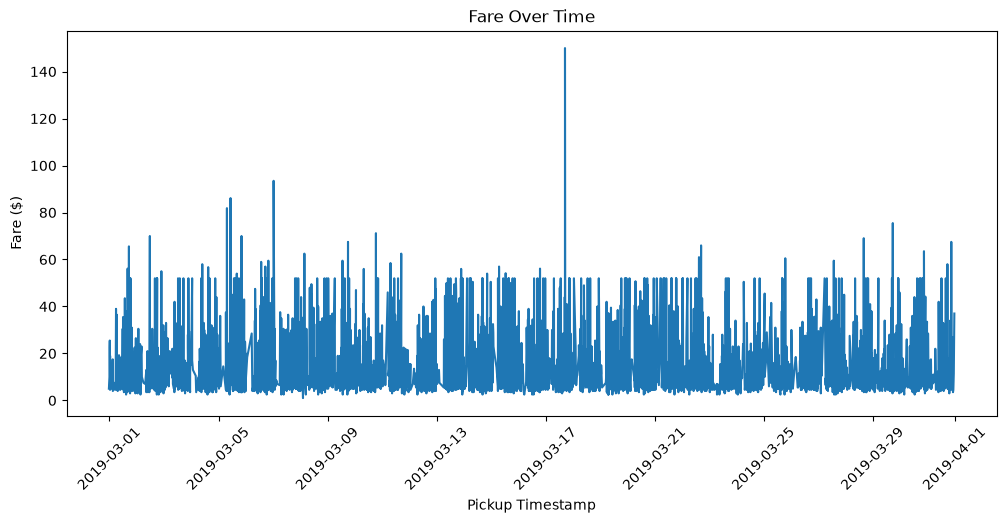

In [38]:
import pandas as pd

df["pickup"]  =  pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

line_df = df.sort_values("pickup")
plt.figure(figsize=(12, 5))
plt.plot(line_df["pickup"], line_df["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.show()

pickup_borough
Bronx         2078.91
Brooklyn      6227.48
Manhattan    58323.92
Queens       15541.06
Name: fare, dtype: float64


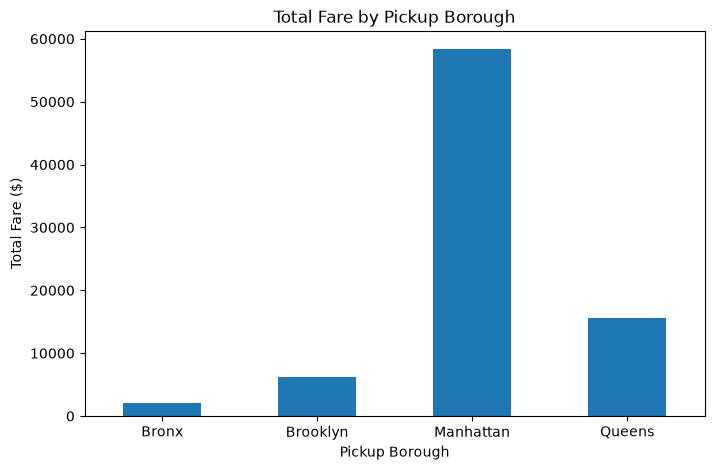

In [39]:
fare_by_borough = df.groupby("pickup_borough")["fare"].sum()
print(fare_by_borough)

plt.figure(figsize=(8, 5))
fare_by_borough.plot(kind="bar")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.show()

payment
credit card    4588
cash           1795
Name: count, dtype: int64


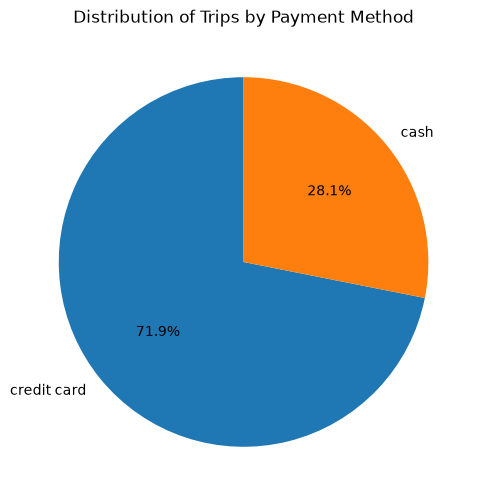

In [40]:
payment_counts = df["payment"].value_counts()
print(payment_counts)

plt.figure(figsize=(6, 6))
payment_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.ylabel("")
plt.show()

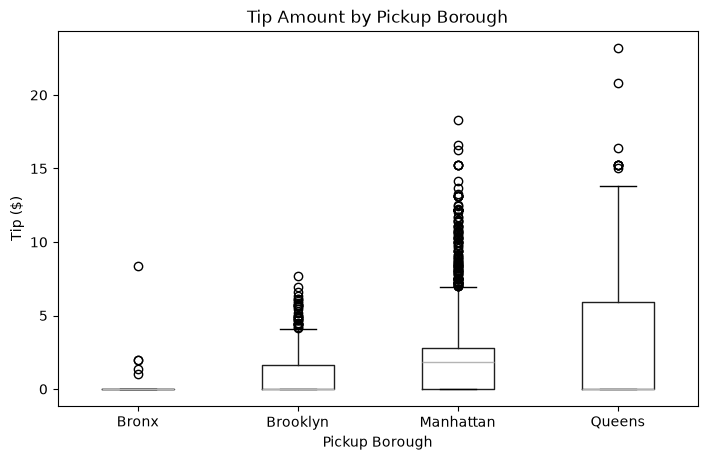

In [41]:
df.boxplot(column="tip", by="pickup_borough", grid=False, figsize=(8, 5))
plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.show()

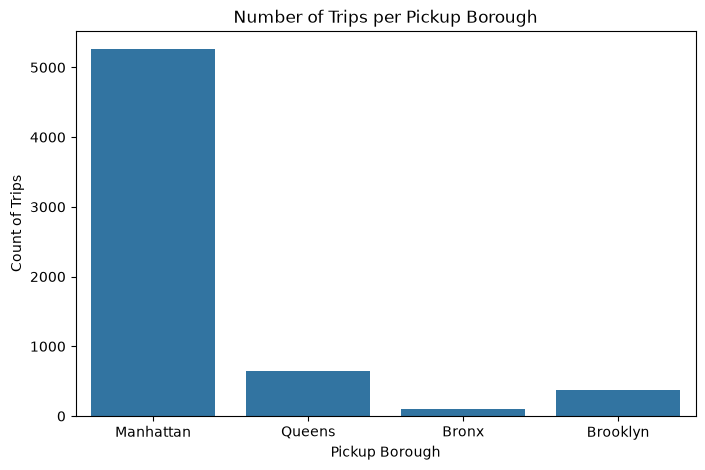

In [42]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips per Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Count of Trips")
plt.show()

Scatter plot

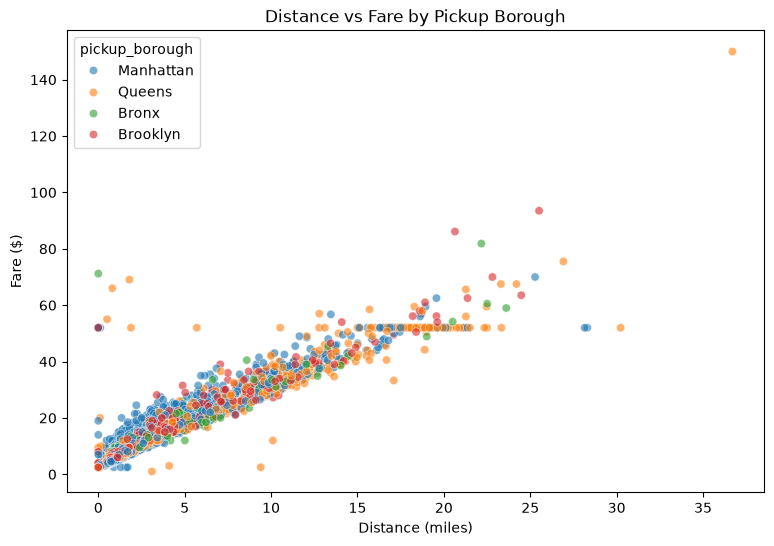

In [43]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=0.6)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

Heatmap

          distance      fare       tip     tolls     total
distance  1.000000  0.947021  0.475378  0.642899  0.928371
fare      0.947021  1.000000  0.485655  0.618184  0.972376
tip       0.475378  0.485655  1.000000  0.412787  0.649050
tolls     0.642899  0.618184  0.412787  1.000000  0.691506
total     0.928371  0.972376  0.649050  0.691506  1.000000


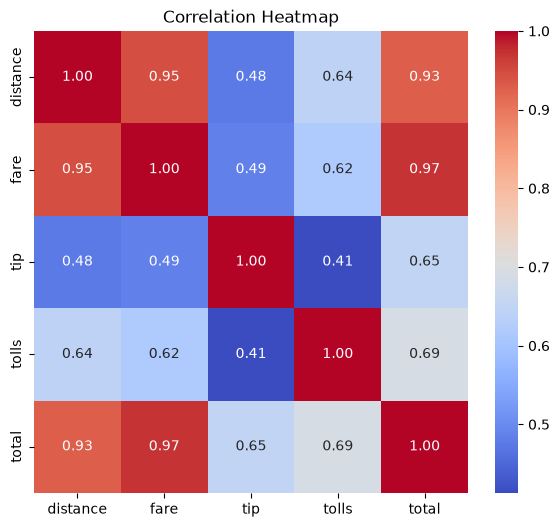

In [44]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
print(corr)

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Pair plot

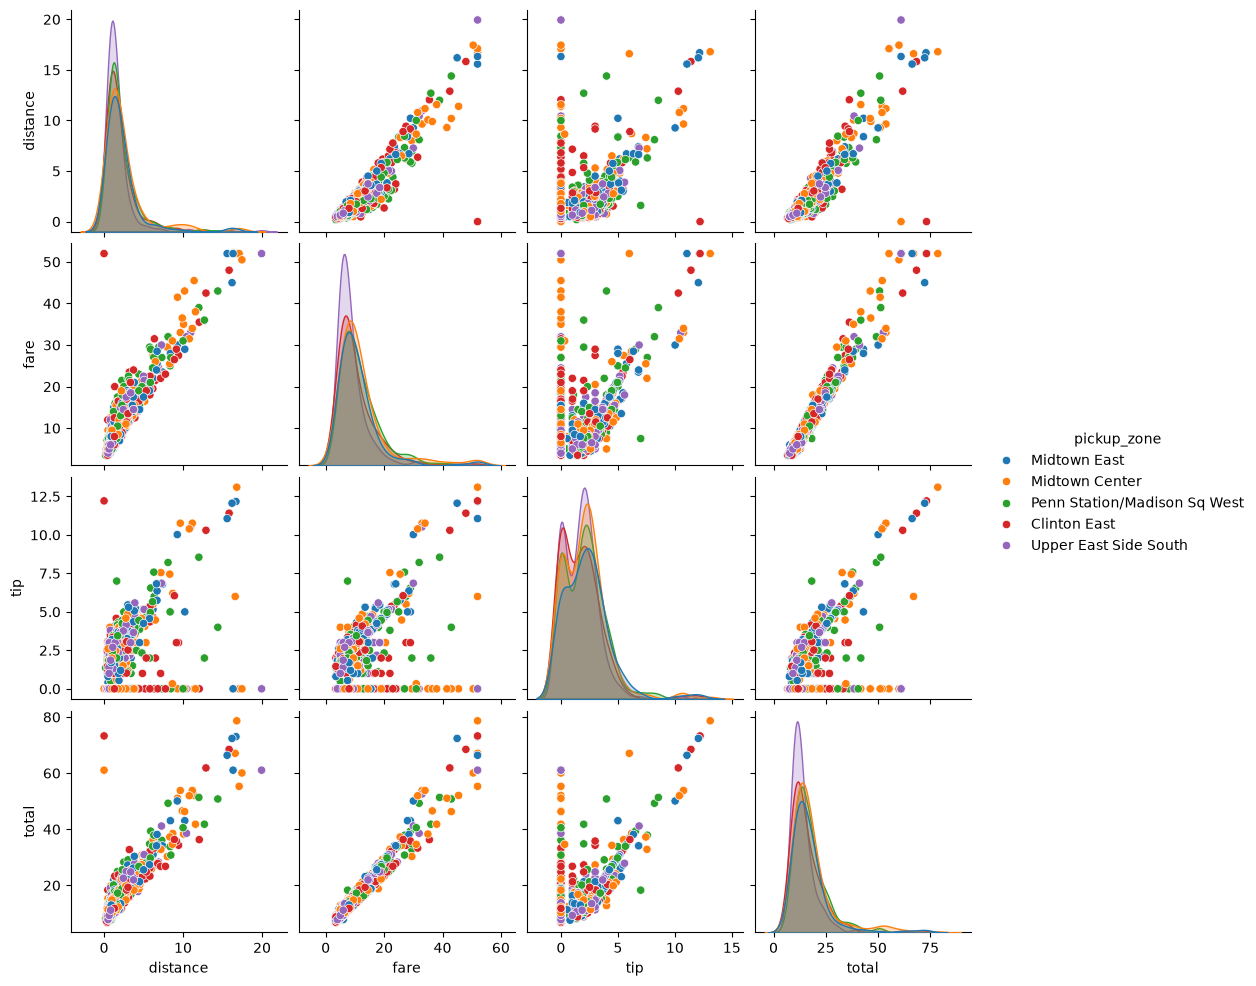

In [45]:
top_zones = df["pickup_zone"].value_counts().head(5).index
pair_df = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(pair_df, vars=["distance", "fare", "tip", "total"], hue="pickup_zone")
plt.show()

Violin plot

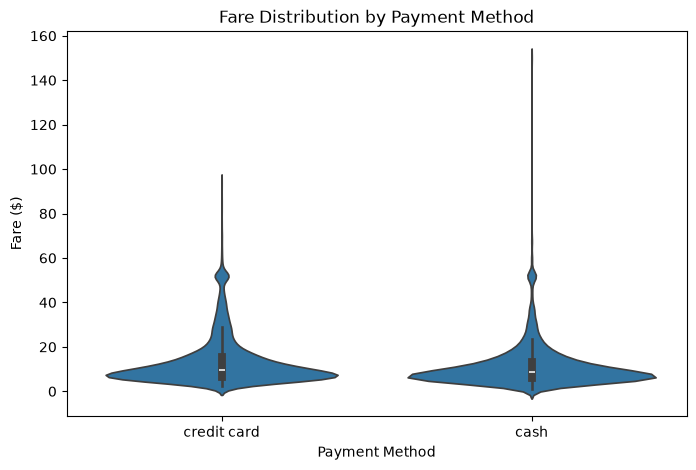

In [46]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.show()